Customer Dataset:
  Customer_ID  Age  Gender   Location  Purchase_Frequency  Total_Purchases  \
0        C001   22  Female    Chennai                   8               10   
1        C002   35    Male  Bengaluru                   5                6   
2        C003   41  Female    Chennai                  12               15   
3        C004   28    Male  Hyderabad                   4                5   
4        C005   52  Female     Mumbai                  10               12   

   Total_Spending  Average_Order_Value Product_Category  
0            7200                  720      Electronics  
1           14500                 2417          Fashion  
2           28600                 1907          Grocery  
3            8200                 1640      Electronics  
4           35400                 2950  Home Appliances  

Dataset Shape: (30, 9)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 9 columns):
 #   Column      

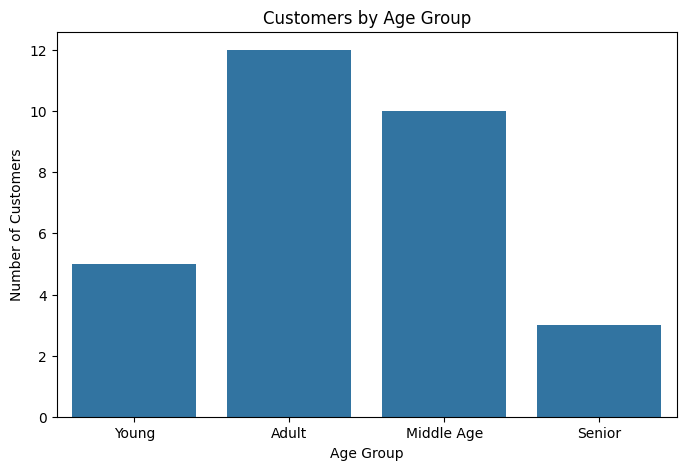

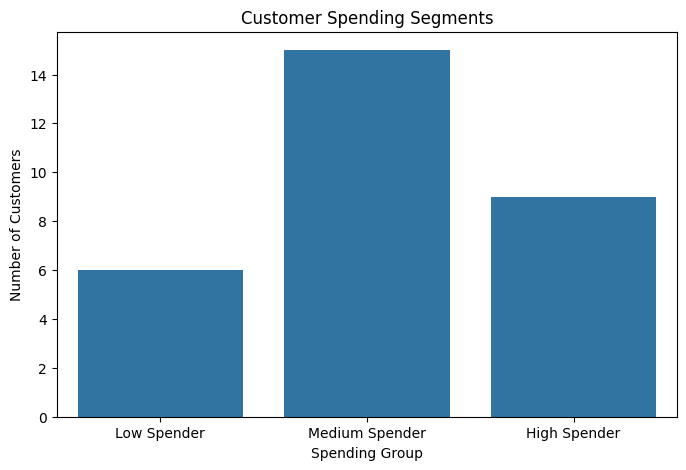

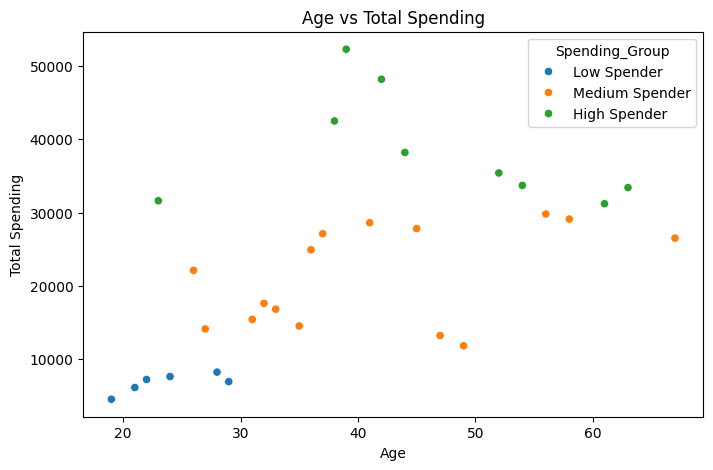

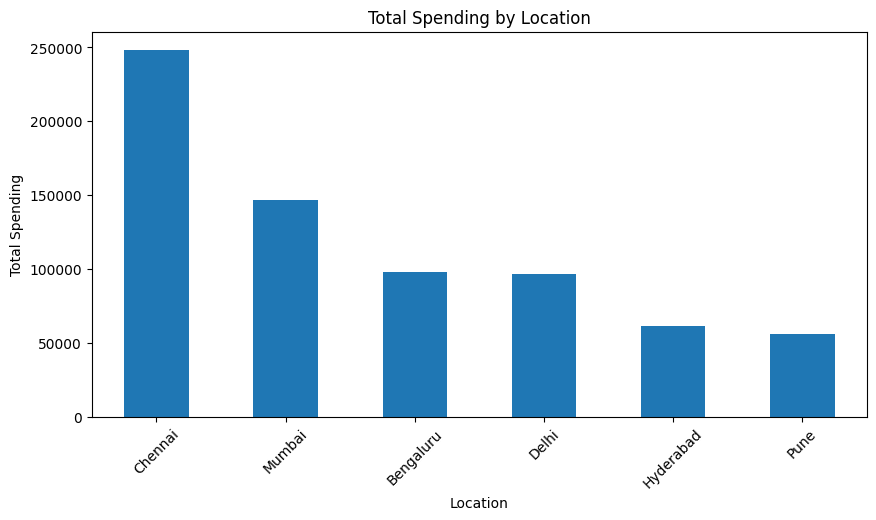

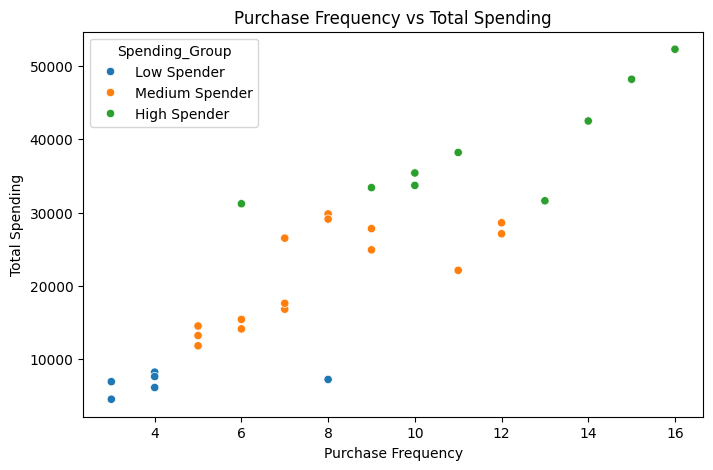

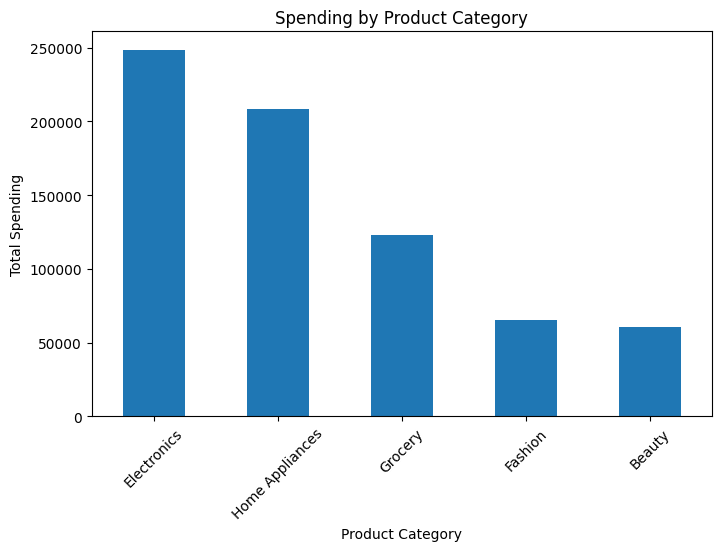

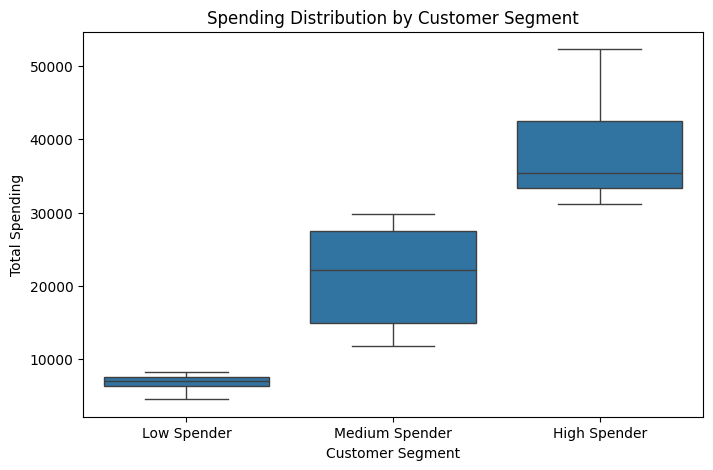

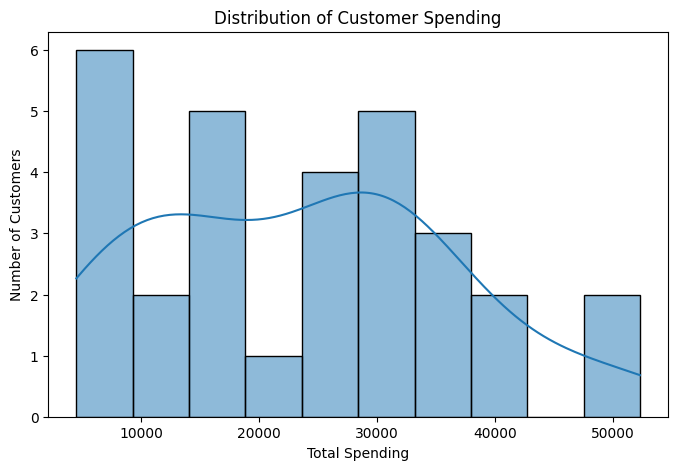


CUSTOMER INSIGHTS

1. Customer Segmentation:
Spending_Group
Medium Spender    15
High Spender       9
Low Spender        6
Name: count, dtype: int64

2. Most Valuable Customer Group:
Spending_Group
High Spender      346500
Medium Spender    319300
Low Spender        40500
Name: Total_Spending, dtype: int64

3. Most Valuable Location:
Chennai

4. Most Valuable Age Group:
Middle Age

5. Most Popular Product Category:
Electronics

6. Highest Spending Product Category:
Electronics

MARKETING STRATEGIES

1. High Spenders:
Provide loyalty rewards, premium offers and exclusive discounts.

2. Medium Spenders:
Use personalized recommendations and limited-time offers.

3. Low Spenders:
Provide introductory discounts and attractive combo offers.

4. Frequent Buyers:
Create loyalty programs and reward points.

5. Location-based Customers:
Provide region-specific promotions based on purchasing behavior.

6. Young Customers:
Use social media campaigns and digital promotions.

7. Low-frequency Custo

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("customer_data.csv")

print("Customer Dataset:")
print(df.head())

print("\nDataset Shape:", df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDescriptive Statistics:")
print(df.describe())

print("\nAverage Total Spending:", df["Total_Spending"].mean())
print("Average Purchase Frequency:", df["Purchase_Frequency"].mean())
print("Average Order Value:", df["Average_Order_Value"].mean())

print("\nTop Customers by Spending:")
print(df.sort_values("Total_Spending", ascending=False).head(10))

def age_group(age):
    if age < 25:
        return "Young"
    elif age < 40:
        return "Adult"
    elif age < 60:
        return "Middle Age"
    else:
        return "Senior"

df["Age_Group"] = df["Age"].apply(age_group)

print("\nCustomers by Age Group:")
print(df["Age_Group"].value_counts())

def spending_group(spending):
    if spending < 10000:
        return "Low Spender"
    elif spending < 30000:
        return "Medium Spender"
    else:
        return "High Spender"

df["Spending_Group"] = df["Total_Spending"].apply(spending_group)

print("\nCustomer Spending Segments:")
print(df["Spending_Group"].value_counts())

valuable_customers = df.sort_values(
    by=["Total_Spending", "Purchase_Frequency"],
    ascending=False
)

print("\nMost Valuable Customers:")
print(valuable_customers[
    ["Customer_ID", "Age", "Location",
     "Purchase_Frequency", "Total_Spending"]
].head(10))

location_analysis = df.groupby("Location").agg({
    "Customer_ID": "count",
    "Total_Spending": "sum",
    "Purchase_Frequency": "mean"
}).sort_values("Total_Spending", ascending=False)

print("\nLocation-wise Customer Analysis:")
print(location_analysis)

category_analysis = df.groupby("Product_Category").agg({
    "Customer_ID": "count",
    "Total_Spending": "sum",
    "Purchase_Frequency": "mean"
}).sort_values("Total_Spending", ascending=False)

print("\nProduct Category Analysis:")
print(category_analysis)

age_analysis = df.groupby("Age_Group").agg({
    "Customer_ID": "count",
    "Total_Spending": "sum",
    "Purchase_Frequency": "mean"
}).sort_values("Total_Spending", ascending=False)

print("\nAge Group Analysis:")
print(age_analysis)

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Age_Group")
plt.title("Customers by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.show()

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Spending_Group")
plt.title("Customer Spending Segments")
plt.xlabel("Spending Group")
plt.ylabel("Number of Customers")
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Age",
    y="Total_Spending",
    hue="Spending_Group"
)
plt.title("Age vs Total Spending")
plt.xlabel("Age")
plt.ylabel("Total Spending")
plt.show()

plt.figure(figsize=(10, 5))
location_analysis["Total_Spending"].plot(kind="bar")
plt.title("Total Spending by Location")
plt.xlabel("Location")
plt.ylabel("Total Spending")
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Purchase_Frequency",
    y="Total_Spending",
    hue="Spending_Group"
)
plt.title("Purchase Frequency vs Total Spending")
plt.xlabel("Purchase Frequency")
plt.ylabel("Total Spending")
plt.show()

plt.figure(figsize=(8, 5))
category_analysis["Total_Spending"].plot(kind="bar")
plt.title("Spending by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Spending")
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="Spending_Group",
    y="Total_Spending"
)
plt.title("Spending Distribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Spending")
plt.show()

plt.figure(figsize=(8, 5))
sns.histplot(df["Total_Spending"], bins=10, kde=True)
plt.title("Distribution of Customer Spending")
plt.xlabel("Total Spending")
plt.ylabel("Number of Customers")
plt.show()

print("\nCUSTOMER INSIGHTS")

print("\n1. Customer Segmentation:")
print(df["Spending_Group"].value_counts())

print("\n2. Most Valuable Customer Group:")
print(df.groupby("Spending_Group")["Total_Spending"].sum().sort_values(ascending=False))

print("\n3. Most Valuable Location:")
print(location_analysis["Total_Spending"].idxmax())

print("\n4. Most Valuable Age Group:")
print(age_analysis["Total_Spending"].idxmax())

print("\n5. Most Popular Product Category:")
print(category_analysis["Customer_ID"].idxmax())

print("\n6. Highest Spending Product Category:")
print(category_analysis["Total_Spending"].idxmax())

print("""
MARKETING STRATEGIES

1. High Spenders:
Provide loyalty rewards, premium offers and exclusive discounts.

2. Medium Spenders:
Use personalized recommendations and limited-time offers.

3. Low Spenders:
Provide introductory discounts and attractive combo offers.

4. Frequent Buyers:
Create loyalty programs and reward points.

5. Location-based Customers:
Provide region-specific promotions based on purchasing behavior.

6. Young Customers:
Use social media campaigns and digital promotions.

7. Low-frequency Customers:
Send personalized offers and re-engagement campaigns.

8. High-performing Product Categories:
Promote popular products through bundles and targeted advertisements.
""")

print("""
CONCLUSION

Customer data analysis helps identify purchasing behavior,
customer segments and valuable customer groups. High-spending
and frequent customers can be targeted through loyalty programs,
personalized offers and premium services. Location, age and
product-category analysis can help businesses improve their
marketing strategies and increase customer retention.
""")